# Manpower July 2024: incidents per unit

Analysis of OPD unit activity, 1-29 July 2024 (18-19 July excluded):
- how many incidents each unit takes on in a day 
- how long each incident takes.

The data ends at 29 July (OPD switched to a new CAD system on 30 July), and this log comes from the old one. 18 and 19 July are dropped entirely (CAD outage night).

In [27]:
import pandas as pd
import matplotlib.pyplot as plt
from box_utils import BOX_ROOT

DATA = BOX_ROOT / "OPD & TAN - Core Workspace" / "OPD - Oakland Police Dept" / "Data" / "Our Data"

july2024 = pd.read_csv(DATA / "Man_Power_2024_July_matched_codes.csv", parse_dates=["Manpower_Record_Time"],
                       dtype={"unit_beat": str}, low_memory=False)

print(july2024.shape)

(174975, 31)


In [28]:
# Global filters for both analyses
# 1. Keep patrol beat cars only (is_patrol)
# 2. Keep status rows only (Record_Type 2); roster and disposition rows have no duration
patrol = july2024[july2024["is_patrol"] & (july2024["Record_Type"] == 2)]
print(patrol.shape)

(70513, 31)


### Incidents per day

count     27.0
mean     141.4
std       22.6
min      101.0
25%      127.0
50%      140.0
75%      155.0
max      201.0
dtype: float64


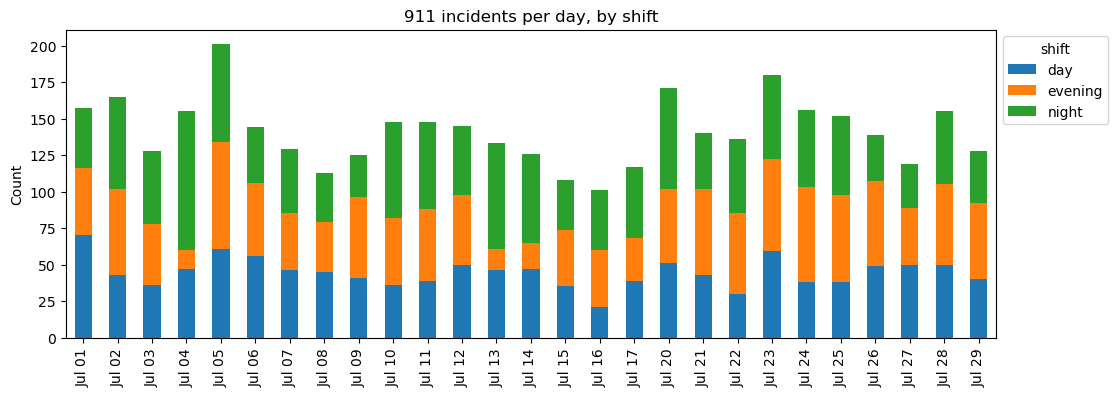

In [29]:
# 911 incidents per day: distinct CAD events (matched_incident_number) that patrol cars worked,
# dated by when they first appear in the log, split by the shift of the first car on it

# one row per incident: its earliest log time and the shift of that first car
events = (patrol[patrol["call_source"] == "911 CALL"].sort_values("Manpower_Record_Time")
                .groupby("matched_incident_number")
                .agg(first_seen=("Manpower_Record_Time", "first"), shift=("shift", "first")))
# date label, e.g. "Jul 01"
events["date"] = events["first_seen"].dt.strftime("%b %d")

# number of incidents per day and shift; columns ordered bottom to top of the stack
per_day = events.groupby(["date", "shift"]).size().unstack()[["day", "evening", "night"]]
print(per_day.sum(axis=1).describe().round(1))

per_day.plot(kind="bar", stacked=True, figsize=(12, 4))
plt.title("911 incidents per day, by shift")
plt.xlabel("")
plt.ylabel("Count")
plt.legend(title="shift", loc="upper left", bbox_to_anchor=(1, 1))
plt.show()

### How many incidents each unit takes on in a day

In [30]:
# 1. Give each row a shift instance: every log on (UO) starts a new shift for that unit
# Need to do this because each unit id may be used again in another day  
rows = patrol.sort_values(["Unit_ID", "Manpower_Record_Time", "Manpower_PK"]).copy()
rows["shift_number"] = (rows["Code"] == "UO").groupby(rows["Unit_ID"]).cumsum()

# 2. Count distinct incidents per shift instance
# list of shifts: each shift has exactly one log on (UO) row, so the UO rows give one row per shift
shifts = rows[rows["Code"] == "UO"].set_index(["Unit_ID", "shift_number"])[["shift"]]
# readable names for the four call sources
SOURCE = {
    "911 CALL":             "911",
    "DEFAULT - PHONE INIT": "non-911 phone",  # exact meaning TBD: phone-started, not flagged as 911
    "FIELD INITIATED BY D": "field-initiated",
    "MDT-INITIATED":        "MDT-initiated",
}
# count unique incidents in each shift for each call source, and add the counts to the list (0 if none)
counts = rows.groupby(["Unit_ID", "shift_number", "call_source"])["Incident_FK"].nunique().unstack()
shifts = shifts.join(counts.rename(columns=SOURCE)).fillna(0)

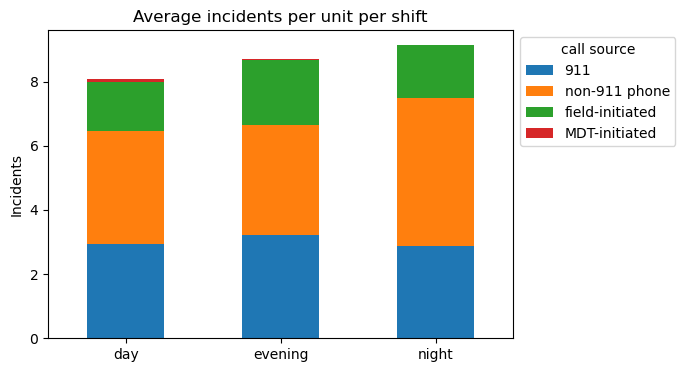

In [31]:
# 3. Plot: average incidents per unit per shift, stacked by call source
avg = shifts.groupby("shift")[list(SOURCE.values())].mean().loc[["day", "evening", "night"]]
avg.plot(kind="bar", stacked=True, rot=0, figsize=(6, 4))
plt.title("Average incidents per unit per shift")
plt.xlabel("")
plt.ylabel("Incidents")
plt.legend(title="call source", loc="upper left", bbox_to_anchor=(1, 1))
plt.show()

           P0    P1    P2    P3    P4    P5  priority unknown
shift                                                        
day      0.00  3.47  3.41  0.99  0.14  0.06              0.12
evening  0.02  3.92  3.27  1.09  0.23  0.18              0.12
night    0.03  4.12  3.75  0.92  0.27  0.06              0.13


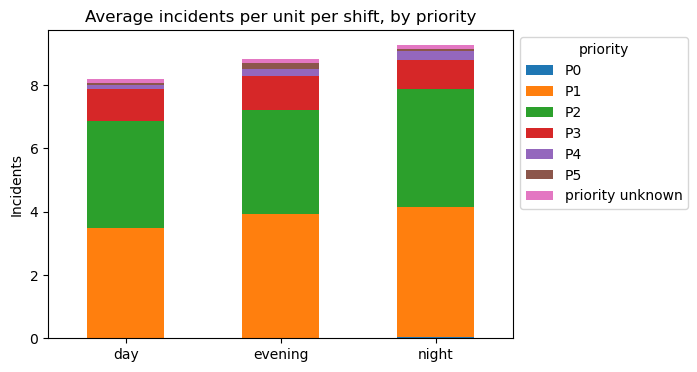

In [32]:
# Same as above, split by incident priority; incidents not linked to CAD have no priority ("priority unknown")
prio = rows.dropna(subset=["Incident_FK"]).copy()
prio["priority"] = prio["incident_priority"].map(lambda p: f"P{int(p)}" if pd.notna(p) else "priority unknown")

# count unique incidents in each shift for each priority (0 if none)
counts = prio.groupby(["Unit_ID", "shift_number", "priority"])["Incident_FK"].nunique().unstack()
by_priority = shifts[["shift"]].join(counts).fillna(0)

PRIORITIES = sorted(c for c in counts.columns if c != "priority unknown") + ["priority unknown"]
avg_priority = by_priority.groupby("shift")[PRIORITIES].mean().loc[["day", "evening", "night"]]
print(avg_priority.round(2))

avg_priority.plot(kind="bar", stacked=True, rot=0, figsize=(6, 4))
plt.title("Average incidents per unit per shift, by priority")
plt.xlabel("")
plt.ylabel("Incidents")
plt.legend(title="priority", loc="upper left", bbox_to_anchor=(1, 1))
plt.show()

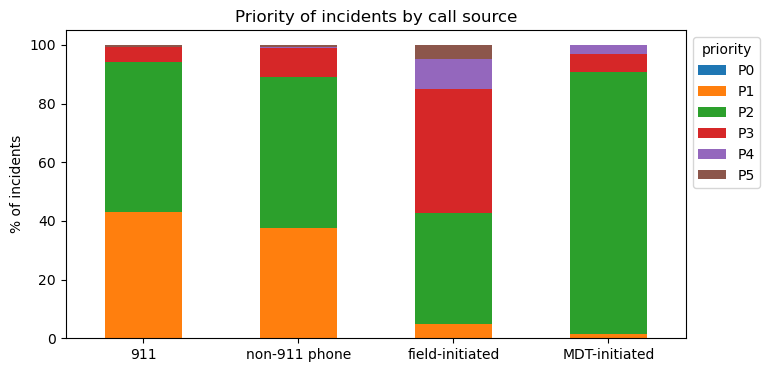

In [33]:
# Priority mix of each call source: one row per incident patrol units worked, percent of incidents in each priority
incident_mix = prio.drop_duplicates("Incident_FK").dropna(subset=["call_source"])
pct = pd.crosstab(incident_mix["call_source"].map(SOURCE), incident_mix["priority"], normalize="index") * 100
pct = pct.loc[list(SOURCE.values()), sorted(pct.columns)]

pct.plot(kind="bar", stacked=True, rot=0, figsize=(8, 4))
plt.title("Priority of incidents by call source")
plt.xlabel("")
plt.ylabel("% of incidents")
plt.legend(title="priority", loc="upper left", bbox_to_anchor=(1, 1))
plt.show()

          incidents  dispatched  arrived
priority                                
P0                2       100.0    100.0
P1             3924        99.0     98.4
P2             9428        92.1     89.4
P3             4439        87.8     85.0
P4             2228        42.1     40.3
P5             1046        24.6     23.9


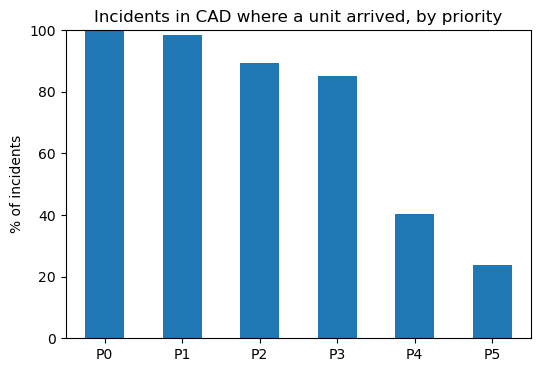

In [34]:
# Share of all incidents in CAD, by priority (same days as the log) that got a unit dispatched (CAD)
# and a unit attended (Man_Power: any unit en route, on scene, officer-initiated, transporting or at / en route to a facility)
cad = pd.read_parquet(DATA / "harmonized_calls_2021_2026.parquet",
                      columns=["event_number", "event_time", "priority", "dispatch_time", "disposition_code"]).drop_duplicates("event_number")
cad["priority"] = pd.to_numeric(cad["priority"], errors="coerce")
day = cad["event_time"].dt.normalize()
in_scope = day.between("2024-07-01", "2024-07-29") & ~day.isin(pd.to_datetime(["2024-07-18", "2024-07-19"]))
# leave out incidents CAD closed as not needing a police unit
NO_UNIT_NEEDED = [
    "FA",     # fire alarm
    "AO",     # ambulance ordered
    "DUP",    # duplicate call
    "CAN",    # cancelled
    "ROA",    # referred to other agency
    "BCAST",  # broadcast
    "COMM",   # comm order broadcast
]
by_prio_cad = cad[in_scope & cad["priority"].notna() & ~cad["disposition_code"].isin(NO_UNIT_NEEDED)].copy()

ATTENDED = ["en route to call", "on scene", "officer-initiated", "transporting a person", "en route to facility", "at facility"]
on_scene_events = july2024.loc[july2024["code_category"].isin(ATTENDED), "matched_incident_number"]
by_prio_cad["arrived"] = by_prio_cad["event_number"].isin(on_scene_events)

handled = by_prio_cad.groupby("priority").agg(incidents=("event_number", "size"),
                                        dispatched=("dispatch_time", lambda s: s.notna().mean() * 100),
                                        arrived=("arrived", lambda s: s.mean() * 100))
handled.index = "P" + handled.index.astype(int).astype(str)
print(handled.round(1))

handled["arrived"].plot(kind="bar", rot=0, figsize=(6, 4))
plt.title("Incidents in CAD where a unit arrived, by priority")
plt.xlabel("")
plt.ylabel("% of incidents")
plt.ylim(0, 100)
plt.show()

          count  median
priority               
P1         3447    11.2
P2         4500   155.6
P3          828   384.9
P4           30   273.7
P5           42    39.3


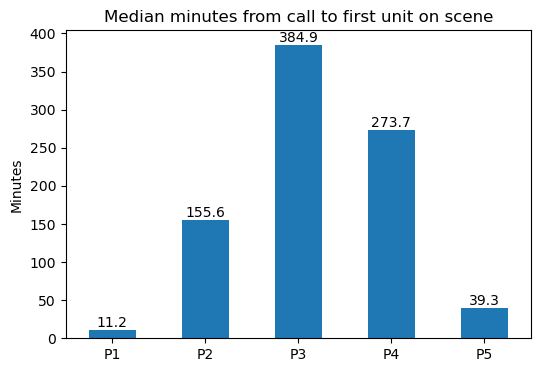

In [35]:
# Median minutes from the call coming in (CAD event_time) to the first unit on scene (Man_Power), by priority;
# 911 and non-911 phone calls only (no officer-initiated), and only incidents with an on-scene status
first_on_scene = july2024[july2024["code_category"] == "on scene"].groupby("matched_incident_number")["Manpower_Record_Time"].min()
sources = pd.read_parquet(DATA / "harmonized_calls_2021_2026.parquet", columns=["event_number", "call_source"]).drop_duplicates("event_number")

calls = by_prio_cad.merge(sources, on="event_number")
calls = calls[calls["call_source"].isin(["911 CALL", "DEFAULT - PHONE INIT"])].copy()
calls["minutes"] = (calls["event_number"].map(first_on_scene) - calls["event_time"]).dt.total_seconds() / 60
calls = calls[calls["minutes"] >= 0]

median_minutes = calls.groupby("priority")["minutes"].agg(["count", "median"])
median_minutes.index = "P" + median_minutes.index.astype(int).astype(str)
print(median_minutes.round(1))

ax = median_minutes["median"].plot(kind="bar", rot=0, figsize=(6, 4))
ax.bar_label(ax.containers[0], fmt="%.1f")
plt.title("Median minutes from call to first unit on scene")
plt.xlabel("")
plt.ylabel("Minutes")
plt.show()

### How long each incident takes 

In [36]:
# 1. Keep only time spent working the incident:
#    drop "available" (already cleared), reassign / freed (instant handovers) and at-station rows;
#    status updates (UU) take the status they continue
work = patrol.copy()
work["code_category"] = work["code_category"].replace("status update", pd.NA)
work["code_category"] = work.groupby("Unit_ID")["code_category"].ffill()
work = work[~work["code_category"].isin(["available", "assignment change", "out of service", "at station after log-on"])]

# 2. Time per unit per incident: sum Seconds_At_Status over that unit's rows on the incident (rows with no incident drop out),
#    in minutes and split by code_category; one row per unit x incident
minutes = (work.groupby(["shift", "shift_hours", "Unit_ID", "Incident_FK", "code_category"])["Seconds_At_Status"].sum() / 60)
minutes = minutes.unstack(fill_value=0).reset_index()

# shift label with its hours, e.g. "day (6/7am-4/5pm)"
minutes["shift_label"] = minutes["shift"] + " (" + minutes["shift_hours"] + ")"
# stages of working an incident, in time order
STAGES = ["officer-initiated", "en route to call", "on scene", "transporting a person",
          "en route to facility", "at facility", "special assignment"]
# total minutes the unit spent on the incident, start to finish
minutes["total"] = minutes[STAGES].sum(axis=1)

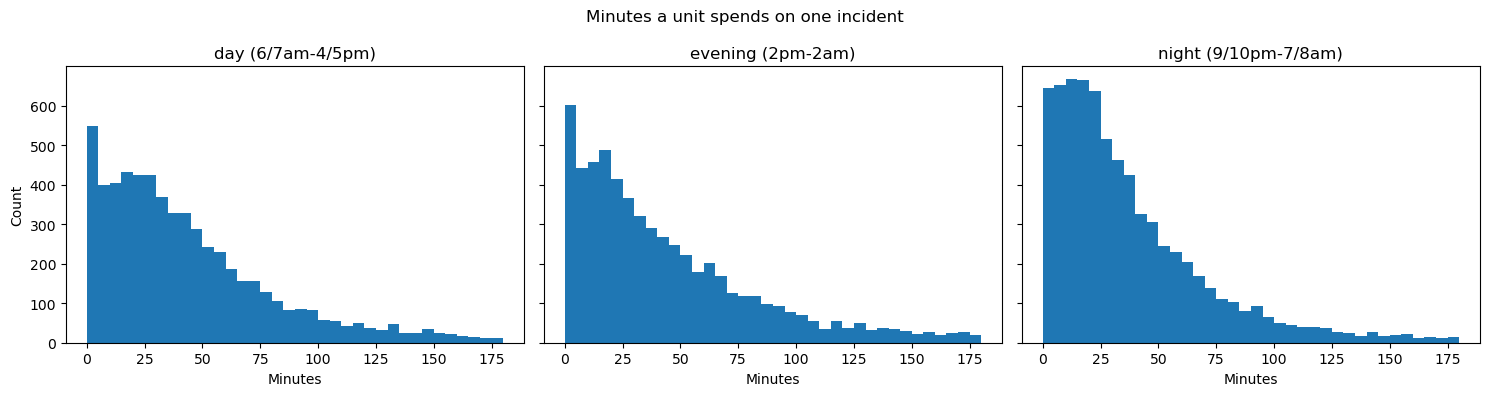

In [37]:
# 3. Plot: how long a unit spends on one incident, start to finish, one histogram per shift (shown up to 3 hours)
SHIFT_LABELS = minutes.drop_duplicates("shift").set_index("shift")["shift_label"][["day", "evening", "night"]]
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharex=True, sharey=True)
for ax, label in zip(axes, SHIFT_LABELS):
    ax.hist(minutes.loc[minutes["shift_label"] == label, "total"], bins=36, range=(0, 180))
    ax.set_title(label)
    ax.set_xlabel("Minutes")
axes[0].set_ylabel("Count")
fig.suptitle("Minutes a unit spends on one incident")
plt.tight_layout()
plt.show()

                   count    50%   mean
priority                              
P0                  35.0  124.9  117.2
P1                8650.0   41.2   64.9
P2                7837.0   27.5   39.2
P3                2241.0   29.9   43.7
P4                 496.0   30.2   58.6
P5                 228.0   20.8   36.6
priority unknown   269.0   38.1   95.6


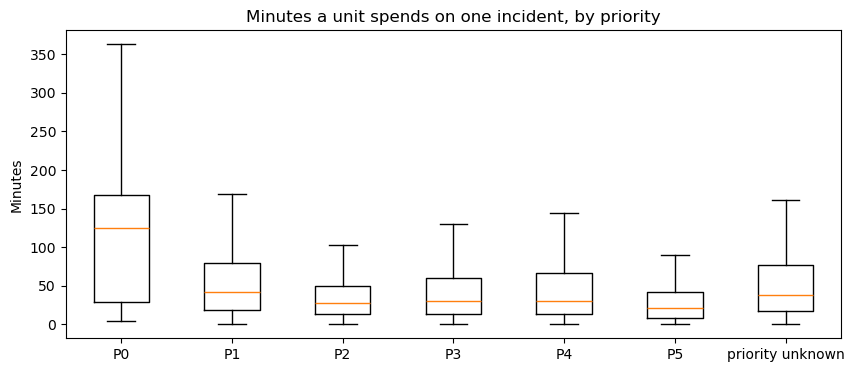

In [38]:
# Minutes a unit spends on one incident, by incident priority; incidents not linked to CAD are "priority unknown"
incident_priority = work.groupby("Incident_FK")["incident_priority"].first()
minutes["priority"] = minutes["Incident_FK"].map(incident_priority).map(lambda p: f"P{int(p)}" if pd.notna(p) else "priority unknown")

PRIORITY_ORDER = sorted(p for p in minutes["priority"].unique() if p != "priority unknown") + ["priority unknown"]
print(minutes.groupby("priority")["total"].describe()[["count", "50%", "mean"]].loc[PRIORITY_ORDER].round(1))

# box plot per priority: box = middle half, line = median, whiskers = typical range (outliers hidden)
plt.figure(figsize=(10, 4))
plt.boxplot([minutes.loc[minutes["priority"] == p, "total"] for p in PRIORITY_ORDER], tick_labels=PRIORITY_ORDER, showfliers=False)
plt.title("Minutes a unit spends on one incident, by priority")
plt.ylabel("Minutes")
plt.show()

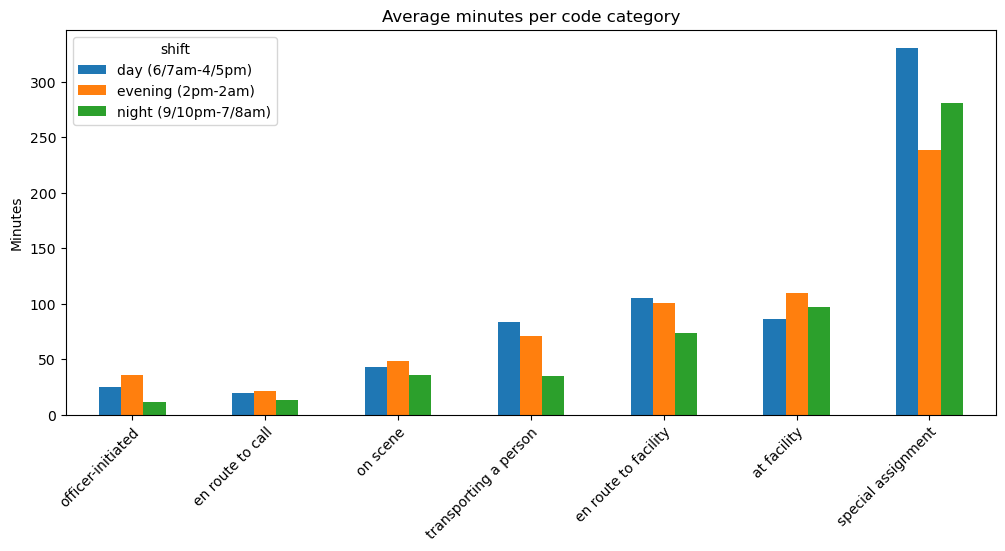

In [39]:
# 4. Plot: average minutes in each code category (only incidents where that stage happened), by shift
stage_avg = minutes[STAGES].where(minutes[STAGES] > 0).groupby(minutes["shift_label"]).mean().loc[SHIFT_LABELS]
stage_avg.T.plot(kind="bar", figsize=(12, 5))
plt.xticks(rotation=45, ha="right", rotation_mode="anchor")
plt.title("Average minutes per code category")
plt.xlabel("")
plt.ylabel("Minutes")
plt.legend(title="shift")
plt.show()

In [40]:
# NEED TO CONTINUE THIS BUT WITH JUST THE 911 CALLS 

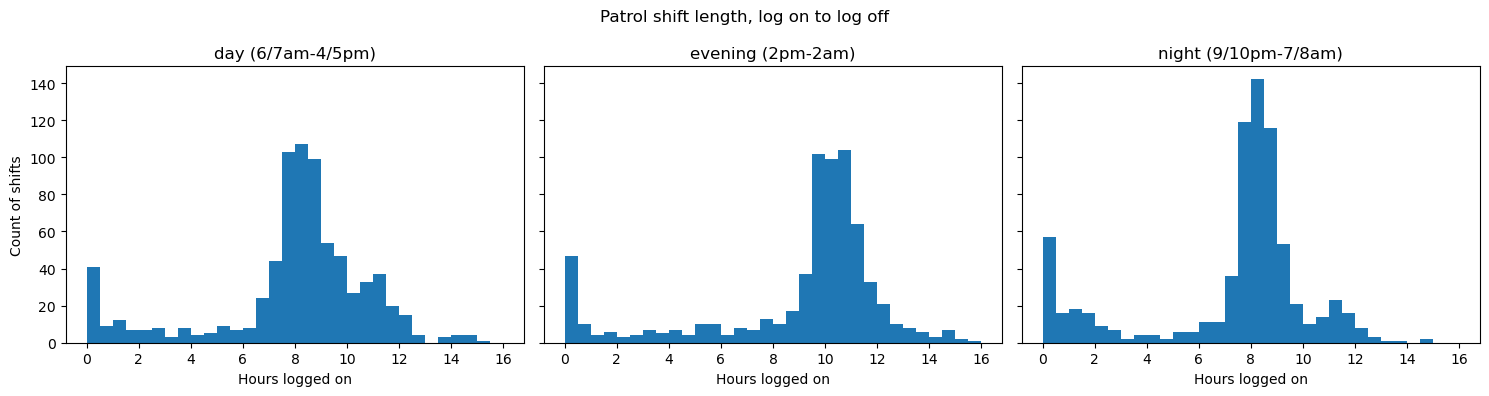

In [41]:
# Shift length for patrol units: log on (UO) to the next log off (UF), using the shift numbers from above
log_on = rows[rows["Code"] == "UO"].groupby(["Unit_ID", "shift_number"])["Manpower_Record_Time"].first()
log_off = rows[rows["Code"] == "UF"].groupby(["Unit_ID", "shift_number"])["Manpower_Record_Time"].first()
shifts["hours"] = (log_off - log_on).dt.total_seconds() / 3600

# Histogram of shift length, one per shift (shown up to 16 hours)
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharex=True, sharey=True)
for ax, (shift, label) in zip(axes, SHIFT_LABELS.items()):
    ax.hist(shifts.loc[shifts["shift"] == shift, "hours"], bins=32, range=(0, 16))
    ax.set_title(label)
    ax.set_xlabel("Hours logged on")
axes[0].set_ylabel("Count of shifts")
fig.suptitle("Patrol shift length, log on to log off")
plt.tight_layout()
plt.show()

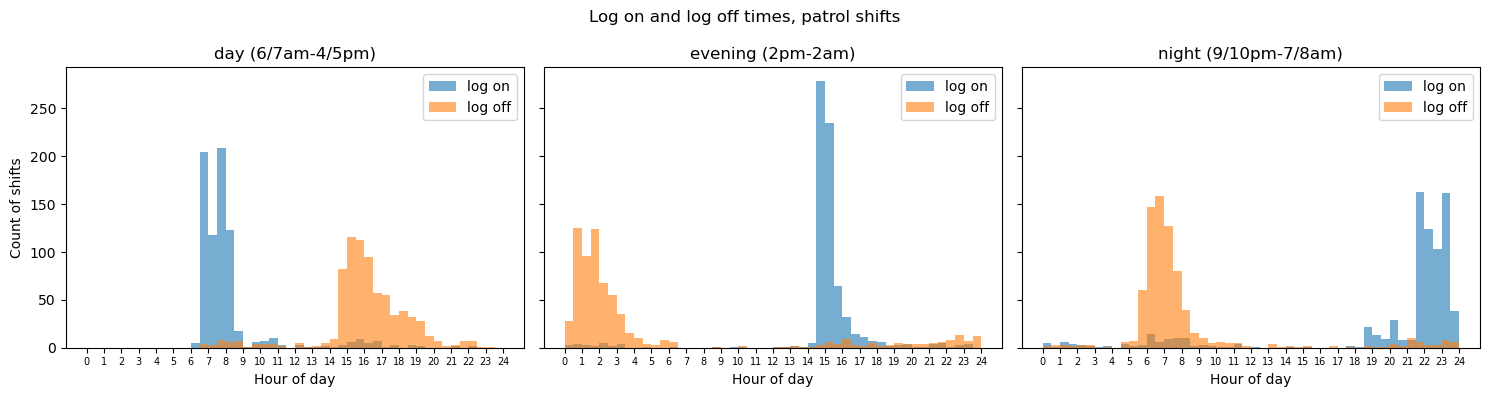

In [51]:
# Clock time (hour of day) of each patrol shift's log on and log off, one chart per shift
times = shifts[["shift"]].assign(log_on=log_on, log_off=log_off)

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, (shift, label) in zip(axes, SHIFT_LABELS.items()):
    one_shift = times[times["shift"] == shift]
    for col in ["log_on", "log_off"]:
        hour = one_shift[col].dt.hour + one_shift[col].dt.minute / 60
        ax.hist(hour, bins=48, range=(0, 24), alpha=0.6, label=col.replace("_", " "))
    ax.set_title(label)
    ax.set_xlabel("Hour of day")
    ax.set_xticks(range(0, 25))
    ax.tick_params(axis="x", labelsize=7)
    ax.legend()
axes[0].set_ylabel("Count of shifts")
fig.suptitle("Log on and log off times, patrol shifts")
plt.tight_layout()
plt.show()

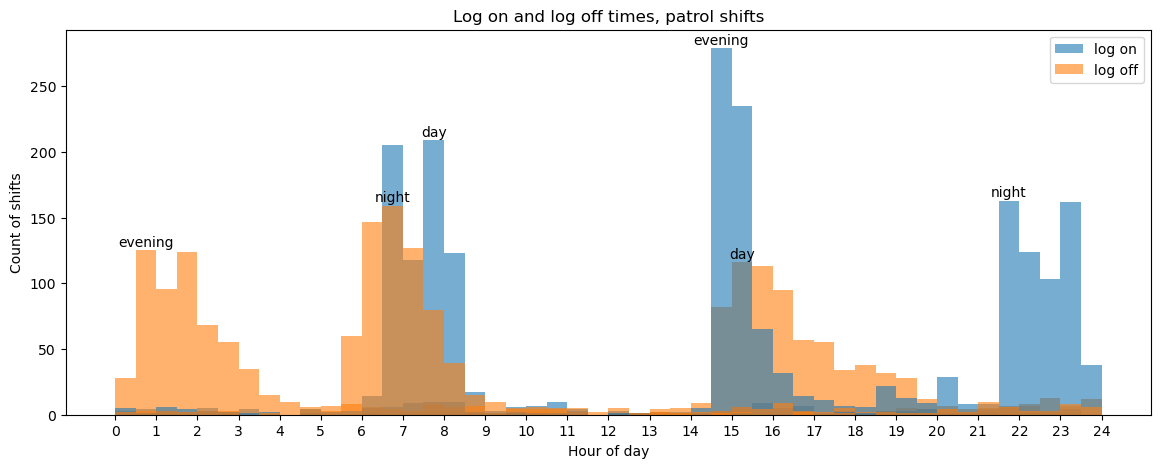

In [50]:
# Log on and log off times for all three shifts in one chart; colors = log on / log off, text = shift
COLORS = {
    "log_on":  "C0",
    "log_off": "C1",
}
plt.figure(figsize=(14, 5))
for shift in ["day", "evening", "night"]:
    one_shift = times[times["shift"] == shift]
    for col, color in COLORS.items():
        hour = one_shift[col].dt.hour + one_shift[col].dt.minute / 60
        counts, edges, _ = plt.hist(hour, bins=48, range=(0, 24), color=color, alpha=0.6,
                                    label=col.replace("_", " ") if shift == "day" else None)
        # shift name above the tallest bar of this group
        peak = counts.argmax()
        plt.text(edges[peak] + 0.25, counts[peak] + 3, shift, ha="center")
plt.title("Log on and log off times, patrol shifts")
plt.xlabel("Hour of day")
plt.ylabel("Count of shifts")
plt.xticks(range(25))
plt.legend()
plt.show()

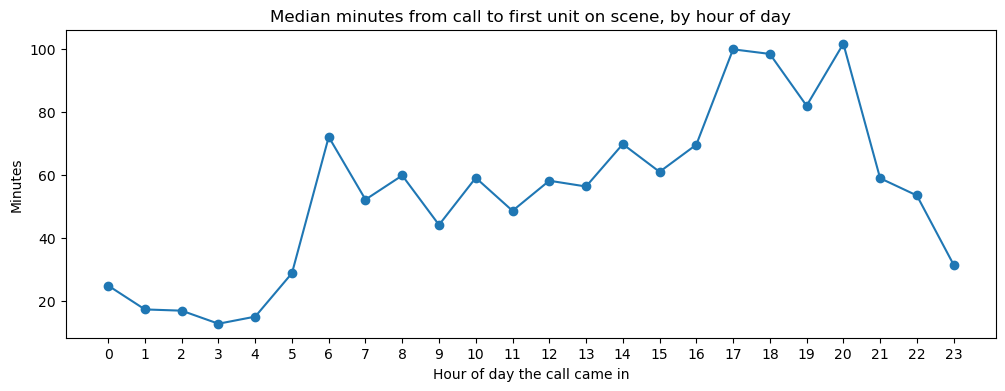

In [43]:
# Median minutes from the call coming in to the first unit on scene, by hour of day the call came in
# (911 and non-911 phone calls timed above, all priorities together)
calls["hour"] = calls["event_time"].dt.hour
response_by_hour = calls.groupby("hour")["minutes"].median()

plt.figure(figsize=(12, 4))
response_by_hour.plot(marker="o")
plt.title("Median minutes from call to first unit on scene, by hour of day")
plt.xlabel("Hour of day the call came in")
plt.ylabel("Minutes")
plt.xticks(range(24))
plt.show()

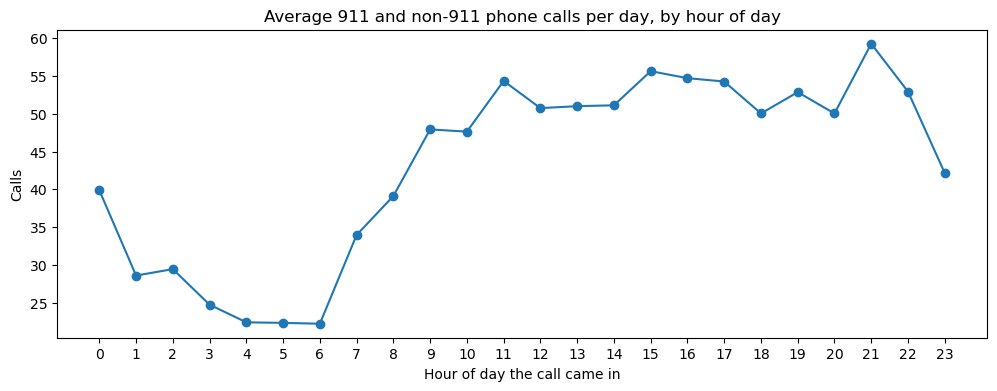

In [44]:
# Call volume: all 911 and non-911 phone calls in CAD on the log days, average per day for each hour
volume_cad = cad[in_scope].merge(sources, on="event_number")
volume_cad = volume_cad[volume_cad["call_source"].isin(["911 CALL", "DEFAULT - PHONE INIT"])]
days = volume_cad["event_time"].dt.normalize().nunique()
volume_by_hour = volume_cad.groupby(volume_cad["event_time"].dt.hour).size() / days

plt.figure(figsize=(12, 4))
volume_by_hour.plot(marker="o")
plt.title("Average 911 and non-911 phone calls per day, by hour of day")
plt.xlabel("Hour of day the call came in")
plt.ylabel("Calls")
plt.xticks(range(24))
plt.show()

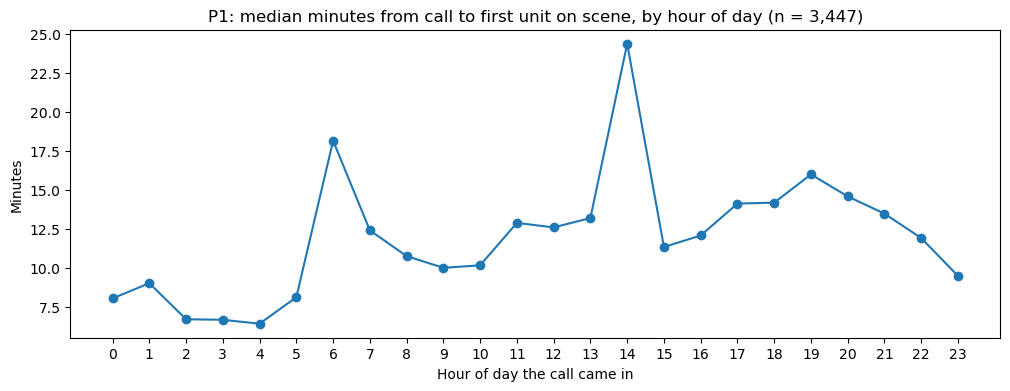

In [56]:
# Median minutes from the call coming in to the first unit on scene, by hour of day, P1 calls only
p1_by_hour = calls[calls["priority"] == 1].groupby("hour")["minutes"].median()
# total number of calls behind the chart
n_calls = (calls["priority"] == 1).sum()

plt.figure(figsize=(12, 4))
p1_by_hour.plot(marker="o")
plt.title(f"P1: median minutes from call to first unit on scene, by hour of day (n = {n_calls:,})")
plt.xlabel("Hour of day the call came in")
plt.ylabel("Minutes")
plt.xticks(range(24))
plt.show()

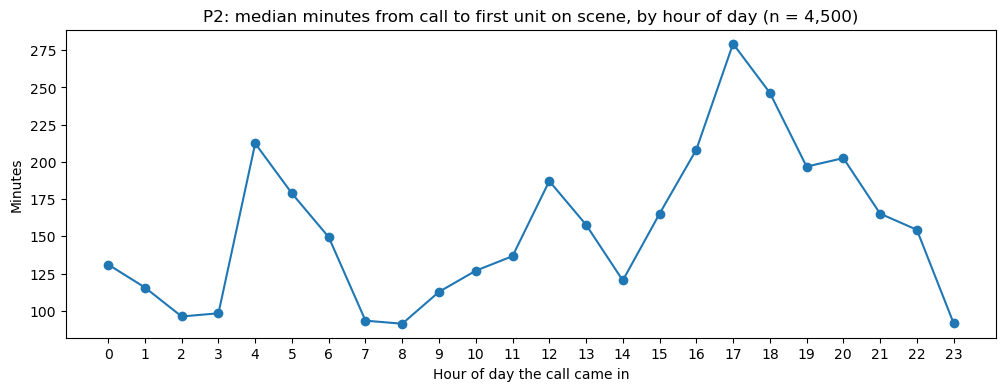

In [57]:
# Median minutes from the call coming in to the first unit on scene, by hour of day, P1 calls only
p1_by_hour = calls[calls["priority"] == 2].groupby("hour")["minutes"].median()
# total number of calls behind the chart
n_calls = (calls["priority"] == 2).sum()

plt.figure(figsize=(12, 4))
p1_by_hour.plot(marker="o")
plt.title(f"P2: median minutes from call to first unit on scene, by hour of day (n = {n_calls:,})")
plt.xlabel("Hour of day the call came in")
plt.ylabel("Minutes")
plt.xticks(range(24))
plt.show()